# Week 4. Convergence of diffusion models

This notebook accompanies Chapter 6 of the notes. Chapter 6 bounds the error of a diffusion model in
terms of three sources: the initialisation from $\mathcal N(0,I_n)$ instead of $q_T$, the learned score, and the time
discretisation. It also explains why the time grid has to become geometric near the end.

1. For Gaussian data and the exact score, the sampler's output is Gaussian and its error can be computed
   exactly. We use this to compare samplers and time grids, for spread-out data and for data close to a
   point mass.
2. We then train a diffusion model on MNIST and sample from it.

Section 1 runs in seconds. Section 2 trains a small neural network. It takes about seven minutes on a recent
laptop GPU (Apple silicon or CUDA) and much longer on a CPU, where you may want to reduce `NUM_STEPS`.

In [1]:
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms

from mnist_unet import UNet

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.manual_seed(4)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: mps


## 1. Exact errors for Gaussian data

Let $q=\mathcal N(0,vI_n)$. Then $q_\tau=\mathcal N(0,\lambda_\tau I_n)$ with $\lambda_\tau=e^{-2\tau}v+1-e^{-2\tau}$, and the exact score is $s_\tau(x)=-x/\lambda_\tau$. On a grid
$0=t_0<\dots<t_K=T-\delta$ with steps $h_k$ and forward levels $\tau_k=T-t_k$, each of the following samplers is a linear
recursion $Y_{k+1}=a_kY_k+b_k\xi_k$, so the output is $\mathcal N(0,P_KI_n)$ with $P_{k+1}=a_k^2P_k+b_k^2$ and $P_0=1$.

- **Euler–Maruyama** for the reverse SDE, $Y_{k+1}=Y_k+h_k[Y_k+2s_{\tau_k}(Y_k)]+\sqrt{2h_k}\,\xi_k$.
- **Exponential integrator** (Chapter 6), which freezes the score on each step and solves the remaining linear SDE
  exactly, $Y_{k+1}=e^{h_k}Y_k+2(e^{h_k}-1)s_{\tau_k}(Y_k)+\sqrt{e^{2h_k}-1}\,\xi_k$.
- **DDPM** (Chapter 7), which freezes the denoised guess of the clean point instead,
  $Y_{k+1}=e^{h_k}[Y_k+(1-e^{-2h_k})s_{\tau_k}(Y_k)]+\sqrt{\tilde\beta_k}\,\xi_k$ with $\tilde\beta_k=(1-e^{-2h_k})\sigma^2_{\tau_{k+1}}/\sigma^2_{\tau_k}$.

The error is $\mathrm{KL}(q_\delta\,\|\,\mathcal N(0,P_KI_n))=\frac n2\bigl(\lambda_\delta/P_K-1-\log(\lambda_\delta/P_K)\bigr)$. We compare two grids with the same number of steps
$K$. The *uniform* grid has equal steps. The *two-phase* grid of Chapter 6 has $K/2$ equal steps on $[0,T-1]$ and $K/2$
steps on $[T-1,T-\delta]$ along which the noise level $T-t_k$ decreases geometrically from $1$ to $\delta$.

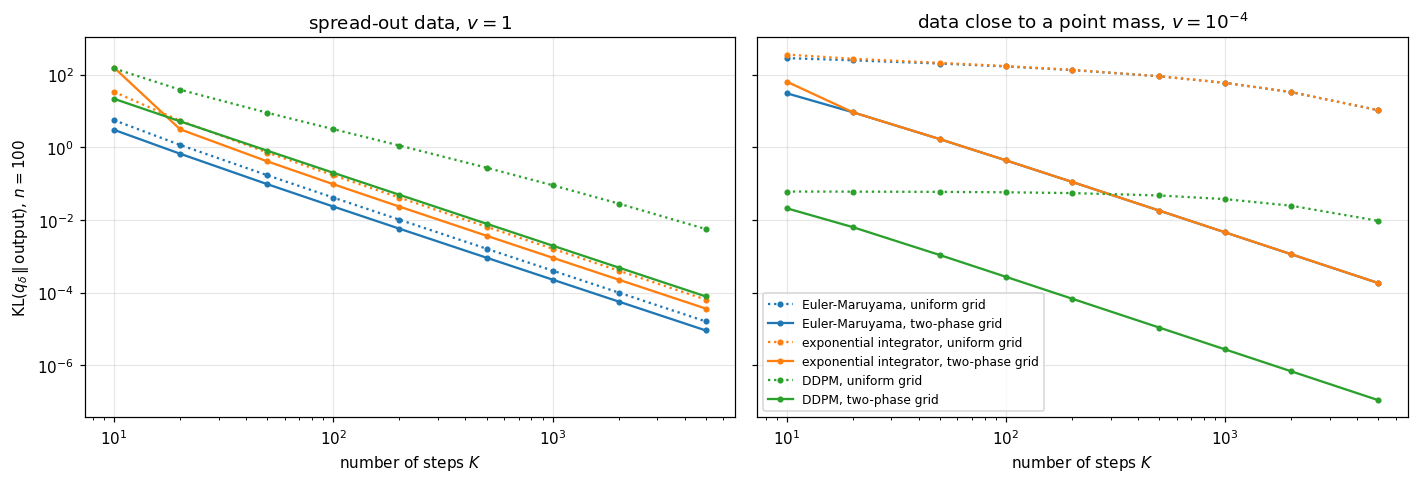

In [2]:
def grid(T, delta, K, kind):
    if kind == "uniform":
        return np.linspace(0, T - delta, K + 1)
    first = np.linspace(0, T - 1, K // 2 + 1)
    second = T - np.geomspace(1.0, delta, K - K // 2 + 1)
    return np.concatenate([first, second[1:]])

def output_variance(v, ts, T, sampler):
    lam = lambda tau: np.exp(-2 * tau) * v + 1 - np.exp(-2 * tau)
    sig2 = lambda tau: 1 - np.exp(-2 * tau)
    P = 1.0
    for t0, t1 in zip(ts[:-1], ts[1:]):
        h, tau0, tau1 = t1 - t0, T - t0, T - t1
        c = -1.0 / lam(tau0)                              # score at level tau0 is c * y
        if sampler == "Euler-Maruyama":
            a, b2 = 1 + h + 2 * h * c, 2 * h
        elif sampler == "exponential integrator":
            a, b2 = np.exp(h) + 2 * (np.exp(h) - 1) * c, np.exp(2 * h) - 1
        else:                                             # DDPM
            a, b2 = np.exp(h) * (1 + (1 - np.exp(-2 * h)) * c), (1 - np.exp(-2 * h)) * sig2(tau1) / sig2(tau0)
        P = a * a * P + b2
    return P

def kl_error(v, K, kind, sampler, n=100, T=8.0, delta=1e-3):
    lam_delta = np.exp(-2 * delta) * v + 1 - np.exp(-2 * delta)
    P = output_variance(v, grid(T, delta, K, kind), T, sampler)
    r = lam_delta / P
    return 0.5 * n * (r - 1 - np.log(r)) if np.isfinite(P) and P > 0 else np.inf

Ks = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000])
samplers = ["Euler-Maruyama", "exponential integrator", "DDPM"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a_, v, title in [(ax[0], 1.0, "spread-out data, $v=1$"), (ax[1], 1e-4, "data close to a point mass, $v=10^{-4}$")]:
    for sampler, color in zip(samplers, ["tab:blue", "tab:orange", "tab:green"]):
        for kind, ls in [("uniform", ":"), ("two-phase", "-")]:
            errs = np.array([kl_error(v, K, kind, sampler) for K in Ks])
            a_.loglog(Ks, errs, ls, color=color, marker="o", ms=3, label=f"{sampler}, {kind} grid")
    a_.set_xlabel("number of steps $K$"); a_.set_title(title)
ax[0].set_ylabel(r"$\mathrm{KL}(q_\delta\,\|\,\mathrm{output})$, $n=100$"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Several lessons can be read off the plots.

- **Spread-out data.** All samplers converge as $K$ grows, and the error decreases like $K^{-2}$. The grid matters
  little for Euler–Maruyama and the exponential integrator, since the score is equally smooth at all noise levels.
- **Data close to a point mass.** The score $-x/\lambda_\tau$ now changes on the time scale $\tau$ near the end. With a uniform grid,
  Euler–Maruyama and the exponential integrator remain very inaccurate even with thousands of steps, because
  their last steps are far too long compared with the remaining noise level. The two-phase grid, whose steps near
  the end are a fixed fraction of the remaining noise level, restores the $K^{-2}$ convergence. This is the reason
  for the step-size condition $h_k\le\kappa\min\{1,T-t_{k+1}\}$ in Chapter 6.
- **DDPM.** It freezes the denoised guess of the clean point rather than the score, and it is exact for a point
  mass, as one of the Week 4 exercises shows. So it is extremely accurate in the second plot, even on the uniform grid. This is the
  mechanism behind its adaptation to data near low-dimensional sets, in Section 6.6. On the uniform grid with
  spread-out data it is less accurate, because its update only agrees with the others to first order when the
  steps are small compared with the noise level.

These are errors of the *final* law. Chapter 6 bounds the relative entropy between the laws of whole paths,
which is larger. For Gaussian data the final error decays like $K^{-2}$, faster than the bound of order $K^{-1}$ for the
path-space error.

*Things to try.* Change $n$. Every error is exactly proportional to $n$ here, because the coordinates are independent.
Change $T$ to $2$ and watch the initialisation error, of order $ne^{-2T}$, take over for large $K$.

## 2. A diffusion model for MNIST

We now train a diffusion model on the $60\,000$ handwritten digits of MNIST, images of $28\times28$ pixels rescaled to
$[-1,1]$, so the dimension is $n=784$. The network (in `mnist_unet.py`) is a small U-Net with about one million
parameters. As in Chapter 4, it predicts the noise $Z$ in $\bar X_\tau=e^{-\tau}\bar X_0+\sigma_\tau Z$, and the score is recovered as
$\hat s_\tau=-\hat Z/\sigma_\tau$. Minimising $\mathbb E|\hat Z-Z|^2$ is denoising score matching with the weight $\sigma_\tau^2$. The noise levels are drawn
log-uniformly between $10^{-3}$ and $T=5$, so that small noise levels, where the score varies fastest, are well
represented.

data: (60000, 1, 28, 28)


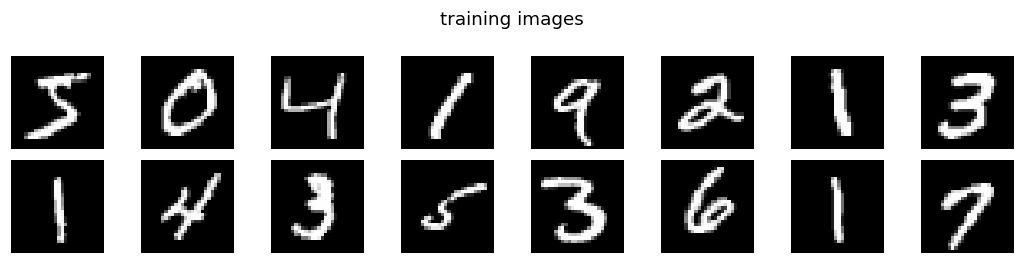

In [3]:
import contextlib, io
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: 2 * x - 1)])
with contextlib.redirect_stderr(io.StringIO()):                 # silence the download progress bars
    mnist = datasets.MNIST(root="data", train=True, download=True, transform=transform)
    mnist_test = datasets.MNIST(root="data", train=False, download=True, transform=transform)
images = torch.stack([mnist[i][0] for i in range(len(mnist))]).to(device)     # (60000, 1, 28, 28)
print("data:", tuple(images.shape))

def show(imgs, nrow=8, title=None, scale=1.2):
    imgs = imgs.detach().clamp(-1, 1).cpu()
    ncol = math.ceil(len(imgs) / nrow)
    fig, ax = plt.subplots(ncol, nrow, figsize=(nrow * scale, ncol * scale))
    for a_, im in zip(np.array(ax).ravel(), imgs):
        a_.imshow(im[0], cmap="gray", vmin=-1, vmax=1)
    for a_ in np.array(ax).ravel():
        a_.axis("off")
    if title: fig.suptitle(title)
    plt.tight_layout(); plt.show()

show(images[:16], title="training images")

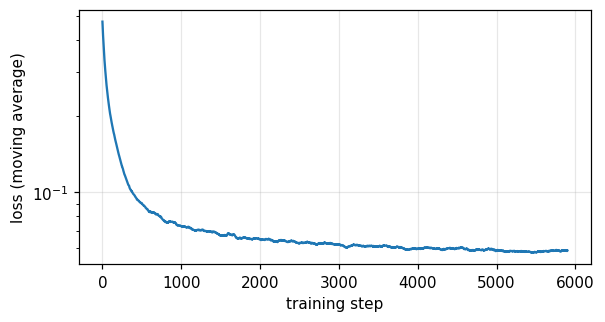

In [4]:
T, TAU_MIN, NUM_STEPS, BATCH = 5.0, 1e-3, 6000, 128
sigma = lambda tau: torch.sqrt(1 - torch.exp(-2 * tau))

def sample_tau(m):
    return torch.exp(math.log(TAU_MIN) + (math.log(T) - math.log(TAU_MIN)) * torch.rand(m, device=device))

model = UNet(base=32).to(device)
ckpt = Path("checkpoints/week4_unet.pt")
if ckpt.exists():
    model.load_state_dict(torch.load(ckpt, map_location=device)); print("loaded", ckpt)
else:
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=NUM_STEPS)
    losses = []
    for step in range(NUM_STEPS):
        x0 = images[torch.randint(0, len(images), (BATCH,), device=device)]
        tau = sample_tau(BATCH); z = torch.randn_like(x0)
        xt = torch.exp(-tau)[:, None, None, None] * x0 + sigma(tau)[:, None, None, None] * z
        loss = ((model(xt, tau) - z)**2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        losses.append(loss.item())
    ckpt.parent.mkdir(exist_ok=True); torch.save(model.state_dict(), ckpt)
    plt.figure(figsize=(6, 3)); plt.semilogy(np.convolve(losses, np.ones(100) / 100, "valid"))
    plt.xlabel("training step"); plt.ylabel("loss (moving average)"); plt.show()
model.eval();

We sample with the exponential integrator on the two-phase grid, starting from $\mathcal N(0,I_n)$ and stopping at
$\delta=10^{-3}$. At the end we apply Tweedie's formula once, $\hat x_0=e^{\delta}(x+\sigma_\delta^2\hat s_\delta(x))$, to remove the small residual noise.

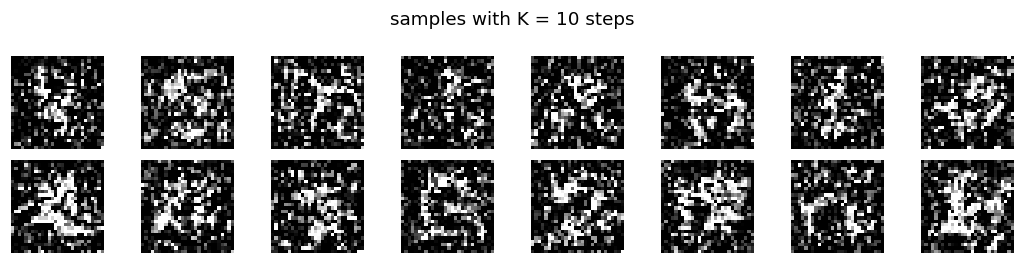

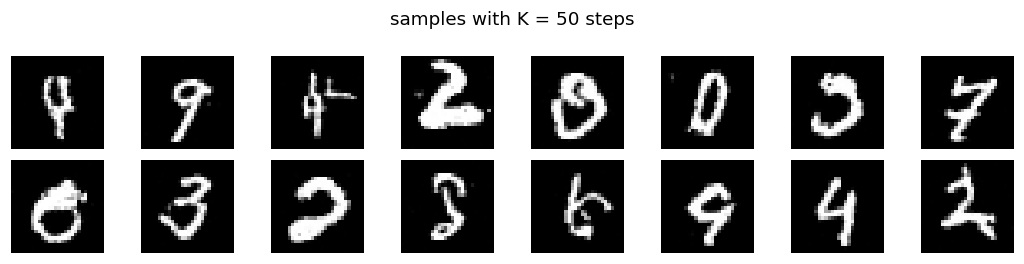

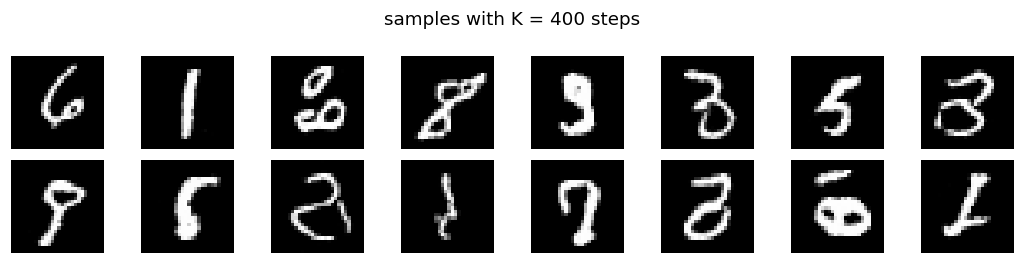

In [5]:
@torch.no_grad()
def sample(model, M, K, delta=1e-3, labels=None, guidance=None):
    ts = grid(T, delta, K, "two-phase")
    y = torch.randn(M, 1, 28, 28, device=device)
    for t0, t1 in zip(ts[:-1], ts[1:]):
        h = float(t1 - t0); tau = torch.full((M,), T - t0, device=device)
        z_hat = model(y, tau) if guidance is None else guidance(y, tau)
        score = -z_hat / sigma(tau)[:, None, None, None]
        y = math.exp(h) * y + 2 * (math.exp(h) - 1) * score + math.sqrt(math.exp(2 * h) - 1) * torch.randn_like(y)
    tau = torch.full((M,), delta, device=device)
    z_hat = model(y, tau) if guidance is None else guidance(y, tau)
    return math.exp(delta) * (y - sigma(tau)[:, None, None, None] * z_hat)       # Tweedie denoising

for K in [10, 50, 400]:
    torch.manual_seed(0)
    show(sample(model, 16, K), title=f"samples with K = {K} steps")

With too few steps the samples are blurry or broken. A few hundred steps of the two-phase grid give recognisable
digits. They are far from perfect, which is mostly due to the small network and the short training.

### Memorisation

A diffusion model trained with the *exact* score of the empirical distribution of the training set would only
reproduce training images, just as a kernel density estimator with a tiny bandwidth does (Chapter 1). A learned
score generalises because the network cannot represent that score. As a sanity check, we look for the nearest
training image of each sample.

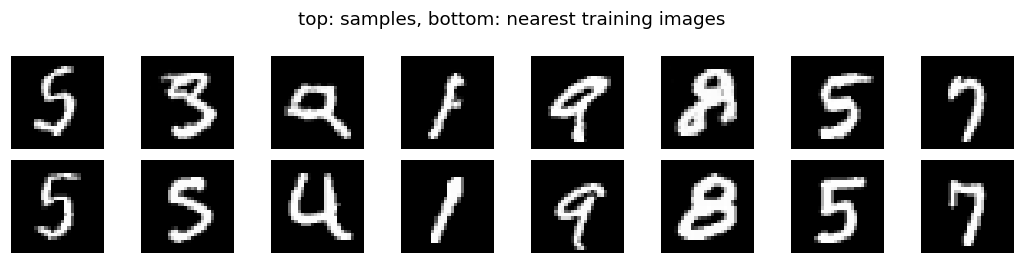

distance of each sample to its nearest training image: [ 8.2 10.3 13.4  6.8 11.1 15.3  9.   6.4]
median distance of a new test-set digit to its nearest training image: 8.8


In [6]:
torch.manual_seed(1)
gen = sample(model, 8, 400)
flat = images.view(len(images), -1)
d2 = torch.cdist(gen.view(8, -1), flat)
nearest = flat[d2.argmin(1)].view(8, 1, 28, 28)
show(torch.cat([gen, nearest]), nrow=8, title="top: samples, bottom: nearest training images")
test = torch.stack([mnist_test[i][0] for i in range(500)]).to(device).view(500, -1)
print("distance of each sample to its nearest training image:", np.round(d2.min(1).values.cpu().numpy(), 1))
print("median distance of a new test-set digit to its nearest training image:",
      round(torch.cdist(test, flat).min(1).values.median().item(), 1))

The samples are not copies of training images. They are about as far from the training set as genuinely new
handwritten digits from the test set are, which is what one expects from samples of the data distribution rather
than of the empirical distribution of the training set.

*Things to try.* Sample with the uniform grid instead of the two-phase grid and the same $K$. Replace the exponential
integrator by Euler–Maruyama. Train for only $1000$ steps and see which features of the digits appear first.